In [4]:
import ssl, certifi
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())

In [10]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0)

# ---------------- data ----------------
def load_cifar(root='./data'):
    tr = torchvision.datasets.CIFAR10(root, train=True, download=True)
    te = torchvision.datasets.CIFAR10(root, train=False, download=True)
    f = lambda d: torch.tensor(d.data).permute(0, 3, 1, 2).float() / 255
    Xtr, Xte = f(tr), f(te)
    mean, std = Xtr.mean((0, 2, 3), keepdim=True), Xtr.std((0, 2, 3), keepdim=True)
    return (Xtr - mean) / std, torch.tensor(tr.targets), (Xte - mean) / std, torch.tensor(te.targets)

def augment(x):
    """Geometry-preserving augmentations: patch i in view A still
    corresponds to patch i in view B (up to a 1-pixel shift)."""
    B = x.shape[0]
    x = x * (1 + 0.4 * (torch.rand(B, 1, 1, 1, device=x.device) - 0.5))  # contrast
    x = x + 0.3 * torch.randn(B, 3, 1, 1, device=x.device)              # color shift
    x = x + 0.1 * torch.randn_like(x)                                     # pixel noise
    dy, dx = torch.randint(-1, 2, (2,)).tolist()
    return torch.roll(x, (dy, dx), (2, 3))                                # tiny translation

pool = lambda h: F.adaptive_avg_pool2d(h, 4).flatten(1)

# ---------------- Fisher discriminant layer ----------------
class FDLayer:
    """Layer = two running outer-product matrices (total and within-pair scatter).
    Filters = top generalized eigenvectors of (S_total, S_within)."""
    def __init__(self, in_ch, k, ks, gamma=1.0, eps=1e-3):
        self.d, self.k, self.ks, self.gamma, self.eps = in_ch * ks * ks, k, ks, gamma, eps
        z = lambda *s: torch.zeros(*s, dtype=torch.float64, device=dev)
        self.n, self.s1, self.s2 = 0.0, z(self.d), z(self.d, self.d)
        self.nw, self.sw = 0.0, z(self.d, self.d)
        self.W = self.mu = None

    def patches(self, x):                                   # (B, d, H*W)
        return F.unfold(x, self.ks, padding=self.ks // 2)

    @torch.no_grad()
    def observe(self, xa, xb, n_pos=64):
        pa, pb = self.patches(xa), self.patches(xb)
        idx = torch.randint(0, pa.shape[2], (n_pos,), device=dev)
        pa = pa[:, :, idx].transpose(1, 2).reshape(-1, self.d)
        pb = pb[:, :, idx].transpose(1, 2).reshape(-1, self.d)
        P, D, g = torch.cat([pa, pb]), pa - pb, self.gamma
        self.n  = g * self.n  + P.shape[0]
        self.s1 = g * self.s1 + P.sum(0).double()
        self.s2 = g * self.s2 + (P.T @ P).double()
        self.nw = g * self.nw + D.shape[0]
        self.sw = g * self.sw + (D.T @ D).double()

    @torch.no_grad()
    def solve(self, random=False):
        mu = self.s1 / self.n
        ST = self.s2 / self.n - torch.outer(mu, mu)
        SW = self.sw / self.nw
        SW = SW + getattr(self, 'beta', 0.0) * ST
        SW = SW + self.eps * SW.trace() / self.d * torch.eye(self.d, dtype=SW.dtype, device=dev)
        if random:
            W = torch.randn(self.d, self.k, dtype=SW.dtype, device=dev) / self.d ** 0.5
        else:
            Linv = torch.linalg.inv(torch.linalg.cholesky(SW))
            M = Linv @ ST @ Linv.T
            _, U = torch.linalg.eigh((M + M.T) / 2)
            W = Linv.T @ U[:, -self.k:].flip(1)             # solves ST w = λ SW w
        self.mu, self.W = mu.float(), W.float()

    def forward(self, x):
        B, _, H, Wd = x.shape
        z = torch.einsum('bdl,dk->bkl', self.patches(x) - self.mu[None, :, None], self.W)
        z = z.reshape(B, self.k, H, Wd)
        return F.avg_pool2d(torch.cat([F.relu(z), F.relu(-z)], 1), 2)

class FDNet:
    def __init__(self, gamma=1.0):
        self.layers = [FDLayer(3, 32, 5, gamma), FDLayer(64, 64, 3, gamma),
                       FDLayer(128, 128, 3, gamma)]
    def run(self, x, upto):
        for l in self.layers[:upto]: x = l.forward(x)
        return x
    def feats(self, x):
        outs = []
        for l in self.layers: x = l.forward(x); outs.append(x)
        return outs

@torch.no_grad()
def fit_fd(net, X, bs=256, random=False):
    for i, layer in enumerate(net.layers):                 # greedy, layer by layer
        for idx in torch.randperm(len(X)).split(bs):
            x = X[idx].to(dev)
            layer.observe(net.run(augment(x), i), net.run(augment(x), i))
        layer.solve(random)

# ---------------- information-form readout ----------------
class RidgeReadout:
    """Additive sufficient statistics + closed-form ridge solve (exact RLS)."""
    def __init__(self, d, c=10, gamma=1.0):
        z = lambda *s: torch.zeros(*s, dtype=torch.float64, device=dev)
        self.A, self.H, self.s, self.ys = z(d, d), z(d, c), z(d), z(c)
        self.n, self.g = 0.0, gamma
    def observe(self, phi, y):
        Y, g = F.one_hot(y, self.H.shape[1]).float(), self.g
        self.A = g * self.A + (phi.T @ phi).double(); self.H = g * self.H + (phi.T @ Y).double()
        self.s = g * self.s + phi.sum(0).double();    self.ys = g * self.ys + Y.sum(0).double()
        self.n = g * self.n + len(phi)
    def solve(self, lam=1e-2):
        m, yb = self.s / self.n, self.ys / self.n
        C = self.A / self.n - torch.outer(m, m)
        sd = C.diagonal().clamp_min(1e-10).sqrt()
        Hc = (self.H / self.n - torch.outer(m, yb)) / sd[:, None]
        I = torch.eye(len(m), dtype=C.dtype, device=dev)
        W = torch.linalg.solve(C / torch.outer(sd, sd) + lam * I, Hc) / sd[:, None]
        self.W, self.b = W.float(), (yb - m @ W).float()
    def predict(self, phi): return phi @ self.W + self.b

@torch.no_grad()
def probe(feat_fn, Xtr, Ytr, Xte, Yte, bs=500):
    heads = None
    for idx in torch.arange(len(Xtr)).split(bs):
        hs = [pool(h) for h in feat_fn(Xtr[idx].to(dev))]
        heads = heads or [RidgeReadout(h.shape[1]) for h in hs]
        for r, h in zip(heads, hs): r.observe(h, Ytr[idx].to(dev))
    for r in heads: r.solve()
    correct = [0] * len(heads)
    for idx in torch.arange(len(Xte)).split(bs):
        for i, (r, h) in enumerate(zip(heads, feat_fn(Xte[idx].to(dev)))):
            correct[i] += (r.predict(pool(h)).argmax(1).cpu() == Yte[idx]).sum().item()
    return [c / len(Xte) for c in correct]

# ---------------- backprop baseline (same widths) ----------------
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        blk = lambda i, o, k: nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2),
                                            nn.BatchNorm2d(o), nn.ReLU(), nn.AvgPool2d(2))
        self.blocks = nn.ModuleList([blk(3, 64, 5), blk(64, 128, 3), blk(128, 256, 3)])
        self.head = nn.Linear(256 * 16, 10)
    def feats(self, x):
        outs = []
        for b in self.blocks: x = b(x); outs.append(x)
        return outs
    def forward(self, x): return self.head(self.feats(x)[-1].flatten(1))

def fit_bp(model, X, Y, epochs=10, bs=256, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr); model.train()
    for _ in range(epochs):
        for idx in torch.randperm(len(X)).split(bs):
            loss = F.cross_entropy(model(augment(X[idx].to(dev))), Y[idx].to(dev))
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()

# ---------------- experiment 1: layer-wise probes ----------------
Xtr, Ytr, Xte, Yte = load_cifar()

fd  = FDNet();          fit_fd(fd, Xtr)
rnd = FDNet();          fit_fd(rnd, Xtr, random=True)
bp  = CNN().to(dev);    fit_bp(bp, Xtr, Ytr)

for name, fn in [('fisher-discriminant', fd.feats), ('random filters', rnd.feats),
                 ('backprop', bp.feats)]:
    print(f'{name:20s}', ['%.3f' % a for a in probe(fn, Xtr, Ytr, Xte, Yte)])

# ---------------- experiment 2: class-incremental ----------------
TASKS = [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)]

@torch.no_grad()
def eval_seen(predict, seen):
    m = torch.isin(Yte, torch.tensor(seen)); X, Y = Xte[m], Yte[m]
    mask = torch.full((10,), float('-inf'), device=dev); mask[seen] = 0
    hits = sum((predict(X[i].to(dev)) + mask).argmax(1).cpu().eq(Y[i]).sum().item()
               for i in torch.arange(len(X)).split(500))
    return hits / len(X)

@torch.no_grad()
def ci_fd(gamma=0.995, bs=256):
    net, head, seen = FDNet(gamma), None, []
    for t, cls in enumerate(TASKS):
        seen += list(cls)
        m = torch.isin(Ytr, torch.tensor(cls)); X, Y = Xtr[m], Ytr[m]
        for i, layer in enumerate(net.layers):              # update + re-solve layers
            for idx in torch.randperm(len(X)).split(bs):
                x = X[idx].to(dev)
                layer.observe(net.run(augment(x), i), net.run(augment(x), i))
            layer.solve()
        for idx in torch.arange(len(X)).split(500):         # readout: old stats used OLD features
            phi = pool(net.feats(X[idx].to(dev))[-1])
            head = head or RidgeReadout(phi.shape[1])
            head.observe(phi, Y[idx].to(dev))
        head.solve()
        acc = eval_seen(lambda x: head.predict(pool(net.feats(x)[-1])), seen)
        print(f'FD  after task {t}: {acc:.3f} on {len(seen)} classes')

def ci_bp(epochs=3):
    model, seen = CNN().to(dev), []
    for t, cls in enumerate(TASKS):
        seen += list(cls)
        m = torch.isin(Ytr, torch.tensor(cls)); fit_bp(model, Xtr[m], Ytr[m], epochs)
        print(f'BP  after task {t}: {eval_seen(model, seen):.3f} on {len(seen)} classes')

ci_fd(); ci_bp()

Files already downloaded and verified
Files already downloaded and verified


KeyboardInterrupt: 

Files already downloaded and verified
Files already downloaded and verified
--- A: layer-wise probe accuracy
uniform-small  ['0.638', '0.698', '0.713']
uniform-large  ['0.642', '0.672', '0.681']
curriculum     ['0.636', '0.690', '0.690']
random         ['0.574', '0.612', '0.626']
backprop       ['0.655', '0.750', '0.811']
--- B: invariance profiles -> invariance.png
--- C: class-incremental, gauge alignment
[raw    ] task 0: all 0.931 | task0 0.931 | drift raw/subspace 
[raw    ] task 1: all 0.414 | task0 0.000 | drift raw/subspace L1 1.25/0.07  L2 1.09/0.76  L3 1.15/0.79
[raw    ] task 2: all 0.295 | task0 0.000 | drift raw/subspace L1 1.64/0.03  L2 1.23/0.60  L3 1.27/0.62
[raw    ] task 3: all 0.239 | task0 0.000 | drift raw/subspace L1 1.59/0.03  L2 1.26/0.55  L3 1.38/0.54
[raw    ] task 4: all 0.187 | task0 0.000 | drift raw/subspace L1 1.46/0.04  L2 1.36/0.41  L3 1.41/0.51
[aligned] task 0: all 0.930 | task0 0.930 | drift raw/subspace 
[aligned] task 1: all 0.418 | task0 0.000 | d

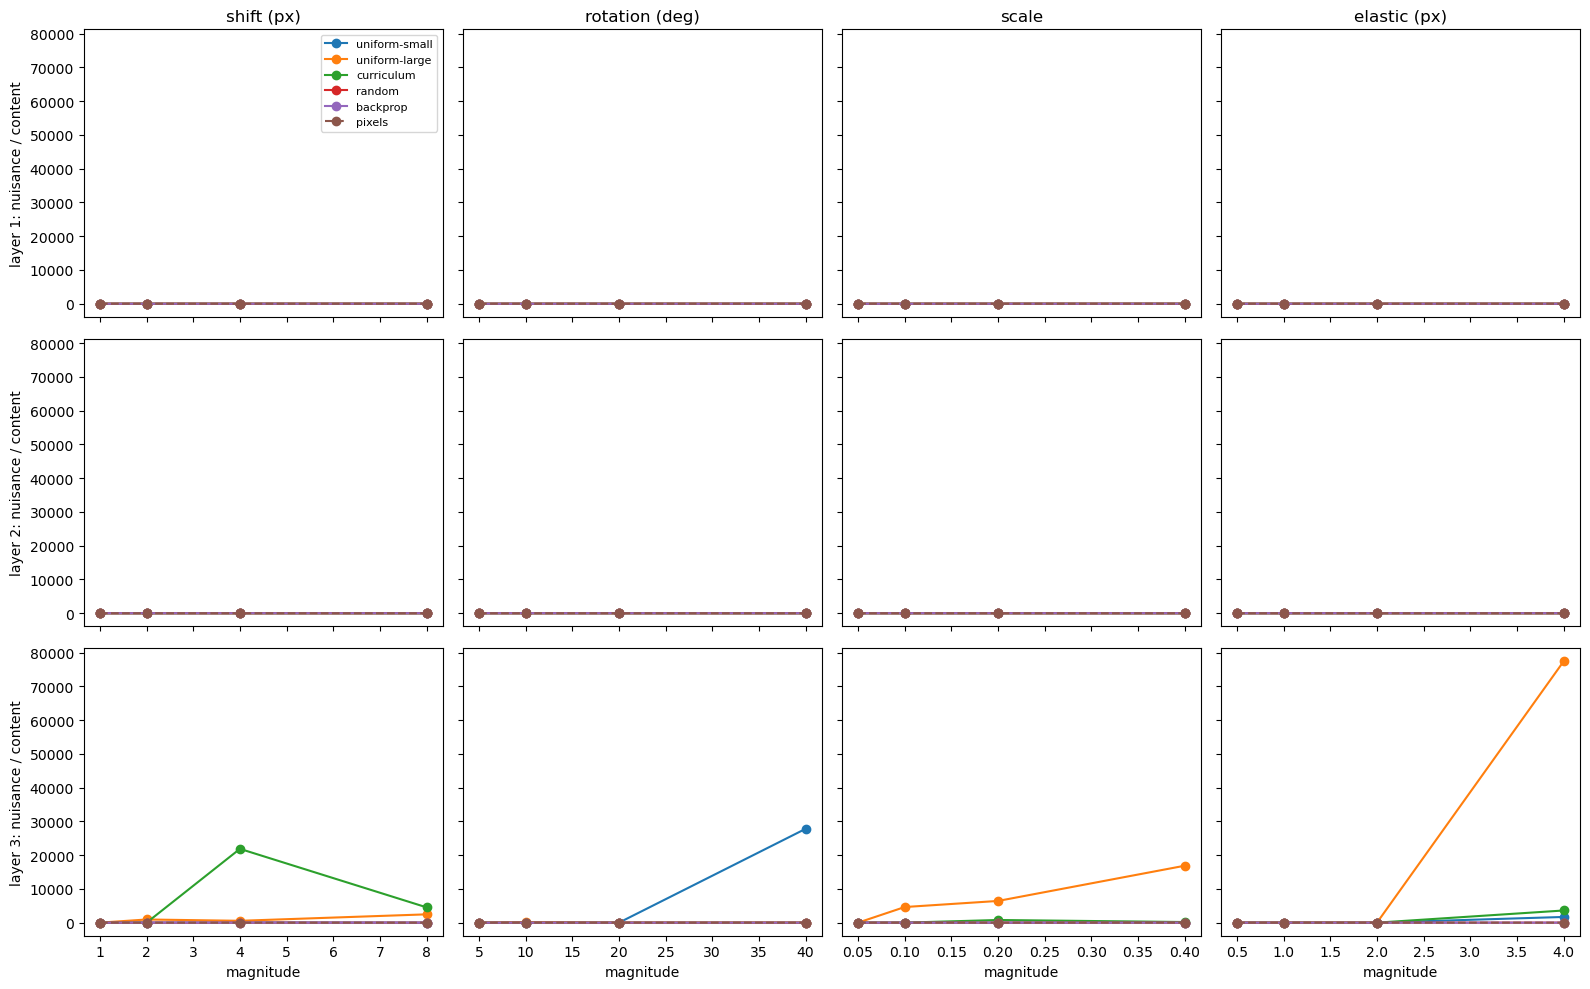

In [6]:
import math
import matplotlib.pyplot as plt

# ---------------- transformations with controllable magnitude ----------------
def warp(x, shift=0., rot=0., scale=0., elastic=0.):
    """Random per-image affine (+ smooth elastic) warp. Units: px, degrees, fraction, px."""
    B, _, H, W = x.shape
    u = lambda: 2 * torch.rand(B, device=x.device) - 1
    th, s = math.radians(rot) * u(), 1 + scale * u()
    tx, ty = 2 * shift / W * u(), 2 * shift / H * u()
    c, n = s * torch.cos(th), s * torch.sin(th)
    A = torch.stack([torch.stack([c, -n, tx], 1), torch.stack([n, c, ty], 1)], 1)
    grid = F.affine_grid(A, x.shape, align_corners=False)
    if elastic > 0:
        disp = F.interpolate(torch.randn(B, 2, 4, 4, device=x.device), size=(H, W),
                             mode='bicubic', align_corners=False)
        grid = grid + (2 * elastic / W) * disp.permute(0, 2, 3, 1)
    return F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)

def photometric(x):
    B = x.shape[0]
    x = x * (1 + 0.4 * (torch.rand(B, 1, 1, 1, device=x.device) - 0.5))
    x = x + 0.3 * torch.randn(B, 3, 1, 1, device=x.device)
    return x + 0.1 * torch.randn_like(x)

def aug(x, cfg): return photometric(warp(x, **cfg))

LARGE = dict(shift=6, rot=20, scale=.2, elastic=1.5)
SCHEDS = {
    'uniform-small': [dict(shift=1)] * 3,
    'uniform-large': [LARGE] * 3,
    'curriculum':    [dict(shift=1), dict(shift=3, rot=10, scale=.1), LARGE],
}

# ---------------- gauge-fixed layer: Procrustes-align after each solve ----------------
class AlignedFDLayer(FDLayer):
    """Filters are only defined up to rotation within the solved subspace.
    Pick the rotation closest to the previous filters (in the S_W metric)."""
    @torch.no_grad()
    def solve(self, random=False):
        old = self.W
        super().solve(random)
        if old is not None and not random:
            SW = self.sw / self.nw
            U, _, Vh = torch.linalg.svd(self.W.double().T @ SW @ old.double())
            self.W = (self.W.double() @ U @ Vh).float()

def make_net(gamma=1.0, aligned=False):
    net = FDNet(gamma)
    if aligned:
        L = AlignedFDLayer
        net.layers = [L(3, 32, 5, gamma), L(64, 64, 3, gamma), L(128, 128, 3, gamma)]
    return net

@torch.no_grad()
def fit_sched(net, X, sched, bs=256, random=False):
    for i, layer in enumerate(net.layers):
        for idx in torch.randperm(len(X)).split(bs):
            x = X[idx].to(dev)
            layer.observe(net.run(aug(x, sched[i]), i), net.run(aug(x, sched[i]), i))
        layer.solve(random)

# ---------------- invariance profile: nuisance / content ratio ----------------
@torch.no_grad()
def pooled(feat_fn, x, bs=500):
    outs = [[pool(h) for h in feat_fn(x[i:i + bs])] for i in range(0, len(x), bs)]
    return [torch.cat(z) for z in zip(*outs)]

@torch.no_grad()
def sensitivity(feat_fn, X, cfg, n=2000):
    """0 = fully invariant; 1 = the transform moves features as far as swapping images."""
    torch.manual_seed(1)                        # identical transforms for every model
    x = X[:n].to(dev)
    xg, perm = warp(x, **cfg), torch.randperm(n, device=dev)
    res = []
    for a, b in zip(pooled(feat_fn, x), pooled(feat_fn, xg)):
        mu, sd = a.mean(0), a.std(0) + 1e-6
        a, b = (a - mu) / sd, (b - mu) / sd
        res.append((((a - b) ** 2).sum(1).mean() / ((a - a[perm]) ** 2).sum(1).mean()).item())
    return res

TRANSFORMS = {
    'shift (px)':     [dict(shift=m) for m in (1, 2, 4, 8)],
    'rotation (deg)': [dict(rot=m) for m in (5, 10, 20, 40)],
    'scale':          [dict(scale=m) for m in (.05, .1, .2, .4)],
    'elastic (px)':   [dict(elastic=m) for m in (.5, 1, 2, 4)],
}

# ---------------- class-incremental with drift diagnostics ----------------
TASKS = [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)]

def filter_drift(Wo, Wn):
    raw = ((Wn - Wo).norm() / Wo.norm()).item()
    Qo, Qn = torch.linalg.qr(Wo)[0], torch.linalg.qr(Wn)[0]
    s = torch.linalg.svdvals(Qo.T @ Qn).clamp(max=1)
    return raw, (1 - s ** 2).mean().sqrt().item()  # raw change, subspace change

@torch.no_grad()
def acc_on(predict, classes, seen):
    m = torch.isin(Yte, torch.tensor(classes)); X, Y = Xte[m], Yte[m]
    mask = torch.full((10,), float('-inf'), device=dev); mask[seen] = 0
    hits = sum((predict(X[i:i + 500].to(dev)) + mask).argmax(1).cpu().eq(Y[i:i + 500]).sum().item()
               for i in range(0, len(X), 500))
    return hits / len(X)

@torch.no_grad()
def ci_test(sched, aligned, gamma=0.995, bs=256):
    net, head, seen = make_net(gamma, aligned), None, []
    for t, cls in enumerate(TASKS):
        seen += list(cls)
        m = torch.isin(Ytr, torch.tensor(cls)); X, Y = Xtr[m], Ytr[m]
        drift = []
        for i, layer in enumerate(net.layers):
            old = None if layer.W is None else layer.W.clone()
            for idx in torch.randperm(len(X)).split(bs):
                x = X[idx].to(dev)
                layer.observe(net.run(aug(x, sched[i]), i), net.run(aug(x, sched[i]), i))
            layer.solve()
            if old is not None: drift.append(filter_drift(old, layer.W))
        for i in range(0, len(X), 500):
            phi = pool(net.feats(X[i:i + 500].to(dev))[-1])
            head = head or RidgeReadout(phi.shape[1])
            head.observe(phi, Y[i:i + 500].to(dev))
        head.solve()
        predict = lambda x: head.predict(pool(net.feats(x)[-1]))
        d = '  '.join(f'L{i + 1} {r:.2f}/{s:.2f}' for i, (r, s) in enumerate(drift))
        print(f'[{"aligned" if aligned else "raw":7s}] task {t}: all {acc_on(predict, seen, seen):.3f}'
              f' | task0 {acc_on(predict, TASKS[0], seen):.3f} | drift raw/subspace {d}')

# ================= run =================
Xtr, Ytr, Xte, Yte = load_cifar()

nets = {}
for name, s in SCHEDS.items():
    nets[name] = make_net(); fit_sched(nets[name], Xtr, s)
nets['random'] = make_net(); fit_sched(nets['random'], Xtr, SCHEDS['uniform-small'], random=True)
bp = CNN().to(dev); fit_bp(bp, Xtr, Ytr)

feat_fns = {k: v.feats for k, v in nets.items()}
feat_fns['backprop'] = bp.feats
feat_fns['pixels'] = lambda x: [x, x, x]

print('--- A: layer-wise probe accuracy')
for name, fn in feat_fns.items():
    if name != 'pixels':
        print(f'{name:14s}', ['%.3f' % a for a in probe(fn, Xtr, Ytr, Xte, Yte)])

print('--- B: invariance profiles -> invariance.png')
fig, ax = plt.subplots(3, 4, figsize=(16, 10), sharex='col', sharey=True)
for j, (tname, cfgs) in enumerate(TRANSFORMS.items()):
    mags = [next(iter(c.values())) for c in cfgs]
    for name, fn in feat_fns.items():
        curves = [sensitivity(fn, Xte, c) for c in cfgs]
        for i in range(3):
            ax[i, j].plot(mags, [c[i] for c in curves], marker='o', label=name,
                          ls='--' if name == 'pixels' else '-')
    ax[0, j].set_title(tname); ax[2, j].set_xlabel('magnitude')
for i in range(3): ax[i, 0].set_ylabel(f'layer {i + 1}: nuisance / content')
ax[0, 0].legend(fontsize=8); fig.tight_layout(); fig.savefig('invariance.png', dpi=120)

print('--- C: class-incremental, gauge alignment')
for aligned in (False, True):
    ci_test(SCHEDS['curriculum'], aligned)

In [7]:
import copy

@torch.no_grad()
def top_feats(net, X):
    return torch.cat([pool(net.feats(X[i:i + 500].to(dev))[-1])
                      for i in range(0, len(X), 500)]).double()

@torch.no_grad()
def transport(head, old_net, new_net, X, lam=1e-1):
    """Fit φ_new ≈ φ_old T + c on current data, then push the readout's
    stored sufficient statistics through that map."""
    P, Q = top_feats(old_net, X), top_feats(new_net, X)
    pm, qm = P.mean(0), Q.mean(0)
    Pc, Qc = P - pm, Q - qm
    I = torch.eye(P.shape[1], dtype=P.dtype, device=dev)
    T = torch.linalg.solve(Pc.T @ Pc + lam * len(P) * Pc.var(0).mean() * I, Pc.T @ Qc)
    c = qm - pm @ T
    Ts = T.T @ head.s
    head.A = T.T @ head.A @ T + torch.outer(Ts, c) + torch.outer(c, Ts) + head.n * torch.outer(c, c)
    head.H = T.T @ head.H + torch.outer(c, head.ys)
    head.s = Ts + head.n * c

@torch.no_grad()
def ci_test(sched, aligned=True, freeze=False, do_transport=False, gamma=0.995, bs=256, tag=''):
    net, head, seen = make_net(gamma, aligned), None, []
    for t, cls in enumerate(TASKS):
        seen += list(cls)
        m = torch.isin(Ytr, torch.tensor(cls)); X, Y = Xtr[m], Ytr[m]
        old_net = copy.deepcopy(net) if t > 0 else None
        if t == 0 or not freeze:
            for i, layer in enumerate(net.layers):
                for idx in torch.randperm(len(X)).split(bs):
                    x = X[idx].to(dev)
                    layer.observe(net.run(aug(x, sched[i]), i), net.run(aug(x, sched[i]), i))
                layer.solve()
        if do_transport and head is not None:
            transport(head, old_net, net, X)
        for i in range(0, len(X), 500):
            phi = pool(net.feats(X[i:i + 500].to(dev))[-1])
            head = head or RidgeReadout(phi.shape[1])
            head.observe(phi, Y[i:i + 500].to(dev))
        head.solve()
        predict = lambda x: head.predict(pool(net.feats(x)[-1]))
        print(f'[{tag:9s}] task {t}: all {acc_on(predict, seen, seen):.3f}'
              f' | task0 {acc_on(predict, TASKS[0], seen):.3f}')

s = SCHEDS['uniform-small']
ci_test(s, freeze=True,         tag='frozen')
ci_test(s, do_transport=True,   tag='transport')
ci_test(s,                      tag='plain')

[frozen   ] task 0: all 0.943 | task0 0.943
[frozen   ] task 1: all 0.836 | task0 0.887
[frozen   ] task 2: all 0.733 | task0 0.885
[frozen   ] task 3: all 0.720 | task0 0.886
[frozen   ] task 4: all 0.712 | task0 0.788
[transport] task 0: all 0.944 | task0 0.944
[transport] task 1: all 0.815 | task0 0.884
[transport] task 2: all 0.697 | task0 0.869
[transport] task 3: all 0.663 | task0 0.849
[transport] task 4: all 0.603 | task0 0.478
[plain    ] task 0: all 0.939 | task0 0.939
[plain    ] task 1: all 0.420 | task0 0.000
[plain    ] task 2: all 0.293 | task0 0.000
[plain    ] task 3: all 0.240 | task0 0.000
[plain    ] task 4: all 0.188 | task0 0.000


In [8]:
print('--- representation learning curve (probe on all 10 classes)')
for k in (1, 2, 5, 10):
    m = Ytr < k                                         # train layers on classes 0..k-1 only
    net = make_net(); fit_sched(net, Xtr[m], SCHEDS['uniform-small'])
    print(f'{k:2d} classes ({m.sum().item():5d} imgs)',
          ['%.3f' % a for a in probe(net.feats, Xtr, Ytr, Xte, Yte)])

idx = torch.randperm(len(Xtr))[:10000]                  # same quantity as 2 classes, full diversity
net = make_net(); fit_sched(net, Xtr[idx], SCHEDS['uniform-small'])
print('10 classes (10000 imgs)', ['%.3f' % a for a in probe(net.feats, Xtr, Ytr, Xte, Yte)])

--- representation learning curve (probe on all 10 classes)
 1 classes ( 5000 imgs) ['0.644', '0.691', '0.416']
 2 classes (10000 imgs) ['0.644', '0.694', '0.718']
 5 classes (25000 imgs) ['0.643', '0.694', '0.721']
10 classes (50000 imgs) ['0.641', '0.695', '0.718']
10 classes (10000 imgs) ['0.639', '0.692', '0.713']


In [9]:
def filter_variance(net, li=2):
    L = net.layers[li]
    mu = L.s1 / L.n
    ST = L.s2 / L.n - torch.outer(mu, mu)
    W = L.W.double(); W = W / W.norm(dim=0)
    v = (W * (ST @ W)).sum(0) / (ST.trace() / L.d)   # filter variance / average direction variance
    return v.min().item(), v.median().item()

net1 = make_net(); fit_sched(net1, Xtr[Ytr < 1], SCHEDS['uniform-small'])
net2 = make_net(); fit_sched(net2, Xtr[Ytr < 2], SCHEDS['uniform-small'])
print('1 class :', filter_variance(net1))
print('2 classes:', filter_variance(net2))

1 class : (0.03309721657199675, 0.1154707719148923)
2 classes: (0.04196845368082809, 0.25626071089544156)


In [11]:
@torch.no_grad()
def amp_ratio(net, li=2):
    """Std of layer output on non-airplane images / on airplane images."""
    a = net.feats(Xte[Yte == 0][:500].to(dev))[li].std()
    b = net.feats(Xte[Yte != 0][:500].to(dev))[li].std()
    return (b / a).item()

def make_net_b(beta):
    net = make_net()
    for L in net.layers: L.beta = beta
    return net

for beta in (0.0, 0.1):
    for k in (1, 2, 10):
        net = make_net_b(beta); fit_sched(net, Xtr[Ytr < k], SCHEDS['uniform-small'])
        acc = probe(net.feats, Xtr, Ytr, Xte, Yte)
        print(f'beta {beta:.1f} | {k:2d} classes', ['%.3f' % a for a in acc],
              f'| amp ratio L3 {amp_ratio(net):.2f}')

beta 0.0 |  1 classes ['0.639', '0.691', '0.696'] | amp ratio L3 1.00
beta 0.0 |  2 classes ['0.640', '0.690', '0.709'] | amp ratio L3 1.00
beta 0.0 | 10 classes ['0.634', '0.689', '0.716'] | amp ratio L3 0.98
beta 0.1 |  1 classes ['0.646', '0.696', '0.714'] | amp ratio L3 1.06
beta 0.1 |  2 classes ['0.643', '0.692', '0.709'] | amp ratio L3 1.02
beta 0.1 | 10 classes ['0.627', '0.696', '0.714'] | amp ratio L3 0.98


In [12]:
# ---------------- warps with known parameters, so they can be inverted ----------------
def sample_warp(B, cfg):
    shift, rot, scale, elastic = (cfg.get(k, 0.) for k in ('shift', 'rot', 'scale', 'elastic'))
    u = lambda: 2 * torch.rand(B, device=dev) - 1
    th, s = math.radians(rot) * u(), 1 + scale * u()
    c, n = s * torch.cos(th), s * torch.sin(th)
    M = torch.stack([torch.stack([c, -n], 1), torch.stack([n, c], 1)], 1)    # (B,2,2), (x,y) order
    t = torch.stack([2 * shift / 32 * u(), 2 * shift / 32 * u()], 1)         # normalized coords
    noise = torch.randn(B, 2, 4, 4, device=dev) * (2 * elastic / 32)
    return M, t, noise

def disp_at(noise, h, w):    # smooth displacement field at any resolution (normalized coords)
    return F.interpolate(noise, size=(h, w), mode='bicubic', align_corners=False).permute(0, 2, 3, 1)

def apply_warp(x, M, t, noise):
    B, _, h, w = x.shape
    grid = F.affine_grid(torch.cat([M, t[:, :, None]], 2), x.shape, align_corners=False)
    return F.grid_sample(x, grid + disp_at(noise, h, w), padding_mode='reflection', align_corners=False)

def unwarp(h, M, t, noise):
    """Resample a feature map of the warped view back into the unwarped view's coordinates."""
    B, _, hh, ww = h.shape
    eye = torch.eye(2, 3, device=dev).repeat(B, 1, 1)
    q = F.affine_grid(eye, h.shape, align_corners=False) - t[:, None, None, :] - disp_at(noise, hh, ww)
    grid = torch.einsum('bij,bhwj->bhwi', torch.linalg.inv(M), q)
    valid = (grid.abs() <= 1).all(-1)                                         # (B,hh,ww)
    return F.grid_sample(h, grid, padding_mode='zeros', align_corners=False), valid

# ---------------- layer with aligned observation and optional random-feature lift ----------------
class RichFDLayer:
    def __init__(self, in_ch, k, ks, expand=0, beta=0.1, eps=1e-3):
        self.in_d, self.k, self.ks = in_ch * ks * ks, k, ks
        self.expand, self.beta, self.eps = expand, beta, eps
        self.R = self.pm = self.rb = self.W = self.mu = None
        self.reset_stats()

    def reset_stats(self):
        d = self.R.shape[1] if self.R is not None else self.in_d
        z = lambda *s: torch.zeros(*s, dtype=torch.float64, device=dev)
        self.n, self.s1, self.s2, self.nw, self.sw = 0.0, z(d), z(d, d), 0.0, z(d, d)

    def lift(self, P):                               # P: (..., in_d)
        return P if self.R is None else F.relu((P - self.pm) @ self.R + self.rb)

    def init_lift(self):
        """Fix a random ReLU expansion scaled to the patch statistics, then restart stats."""
        pm = self.s1 / self.n
        ST = self.s2 / self.n - torch.outer(pm, pm)
        D = self.expand * self.in_d
        self.pm = pm.float()
        self.R = (torch.randn(self.in_d, D, device=dev, dtype=torch.float64) / ST.trace().sqrt()).float()
        self.rb = 0.5 * torch.randn(D, device=dev)
        self.reset_stats()

    def patches(self, x):                            # (B, L, in_d)
        return F.unfold(x, self.ks, padding=self.ks // 2).transpose(1, 2)

    @torch.no_grad()
    def observe(self, xa, xb, valid, n_pos=64):
        pa = self.patches(xa).reshape(-1, self.in_d)
        pb = self.patches(xb).reshape(-1, self.in_d)
        v = valid.reshape(-1).nonzero().squeeze(1)
        sel = v[torch.randperm(len(v), device=dev)[:xa.shape[0] * n_pos]]
        pa, pb = self.lift(pa[sel]), self.lift(pb[sel])
        P, D = torch.cat([pa, pb]), pa - pb
        self.n += P.shape[0];  self.s1 += P.sum(0).double();  self.s2 += (P.T @ P).double()
        self.nw += D.shape[0]; self.sw += (D.T @ D).double()

    @torch.no_grad()
    def solve(self):
        mu = self.s1 / self.n
        ST = self.s2 / self.n - torch.outer(mu, mu)
        SW = self.sw / self.nw + self.beta * ST
        d = len(mu)
        SW = SW + self.eps * SW.trace() / d * torch.eye(d, dtype=SW.dtype, device=dev)
        Linv = torch.linalg.inv(torch.linalg.cholesky(SW))
        M = Linv @ ST @ Linv.T
        _, U = torch.linalg.eigh((M + M.T) / 2)
        self.mu, self.W = mu.float(), (Linv.T @ U[:, -self.k:].flip(1)).float()

    def forward(self, x):
        B, _, H, W = x.shape
        z = (self.lift(self.patches(x)) - self.mu) @ self.W            # (B, L, k)
        z = z.transpose(1, 2).reshape(B, self.k, H, W)
        return F.avg_pool2d(torch.cat([F.relu(z), F.relu(-z)], 1), 2)

def rich_net(expand, beta=0.1):
    net = FDNet()
    net.layers = [RichFDLayer(3, 32, 5, expand, beta), RichFDLayer(64, 64, 3, expand, beta),
                  RichFDLayer(128, 128, 3, expand, beta)]
    return net

@torch.no_grad()
def fit_rich(net, X, sched, bs=256):
    for i, layer in enumerate(net.layers):
        for p in range(2 if layer.expand else 1):    # pass 1 fixes the lift, pass 2 learns
            for idx in torch.randperm(len(X)).split(bs):
                x = X[idx].to(dev)
                M, t, noise = sample_warp(len(x), sched[i])
                ha = net.run(photometric(x), i)
                hb = net.run(photometric(apply_warp(x, M, t, noise)), i)
                hb, valid = unwarp(hb, M, t, noise)
                layer.observe(ha, hb, valid)
            if p == 0 and layer.expand: layer.init_lift()
        layer.solve()

# ---------------- run: configs x data size x seeds ----------------
CURR = SCHEDS['curriculum']
CONFIGS = {
    'baseline (unaligned)':     None,
    'aligned photometric':      dict(sched=[{}] * 3, expand=0),
    'aligned curriculum':       dict(sched=CURR,     expand=0),
    'aligned photometric + RF': dict(sched=[{}] * 3, expand=2),
    'aligned curriculum + RF':  dict(sched=CURR,     expand=2),
}

for name, cfg in CONFIGS.items():
    for n in (5000, 50000):
        accs = []
        for seed in (0, 1):
            torch.manual_seed(seed)
            X = Xtr[torch.randperm(len(Xtr))[:n]]
            if cfg is None:
                net = make_net(); fit_sched(net, X, SCHEDS['uniform-small'])
            else:
                net = rich_net(cfg['expand']); fit_rich(net, X, cfg['sched'])
            accs.append(probe(net.feats, Xtr, Ytr, Xte, Yte, bs=200))
        a = torch.tensor(accs)
        mean, half = a.mean(0), (a.max(0).values - a.min(0).values) / 2
        print(f'{name:26s} n={n:5d}  ' +
              '  '.join(f'L{i + 1} {m:.3f}±{h:.3f}' for i, (m, h) in enumerate(zip(mean, half))))

baseline (unaligned)       n= 5000  L1 0.648±0.002  L2 0.698±0.002  L3 0.724±0.000
baseline (unaligned)       n=50000  L1 0.649±0.002  L2 0.701±0.000  L3 0.723±0.002
aligned photometric        n= 5000  L1 0.637±0.001  L2 0.648±0.001  L3 0.657±0.002
aligned photometric        n=50000  L1 0.636±0.003  L2 0.644±0.002  L3 0.650±0.003
aligned curriculum         n= 5000  L1 0.648±0.004  L2 0.693±0.000  L3 0.708±0.003
aligned curriculum         n=50000  L1 0.647±0.001  L2 0.688±0.003  L3 0.706±0.003
aligned photometric + RF   n= 5000  L1 0.637±0.002  L2 0.656±0.002  L3 0.657±0.003
aligned photometric + RF   n=50000  L1 0.630±0.006  L2 0.654±0.003  L3 0.653±0.002
aligned curriculum + RF    n= 5000  L1 0.627±0.000  L2 0.662±0.001  L3 0.673±0.004
aligned curriculum + RF    n=50000  L1 0.627±0.001  L2 0.664±0.004  L3 0.674±0.008


In [20]:
class LabelFDLayer(FDLayer):
    """Baseline layer plus between-class scatter in the numerator."""
    def __init__(self, *a, alpha=0.0, n_cls=10, **kw):
        super().__init__(*a, **kw)
        self.alpha = alpha
        self.cs = torch.zeros(n_cls, self.d, dtype=torch.float64, device=dev)   # per-class patch sums
        self.cn = torch.zeros(n_cls, dtype=torch.float64, device=dev)

    @torch.no_grad()
    def observe(self, xa, xb, y, n_pos=64):
        pa, pb = self.patches(xa), self.patches(xb)
        idx = torch.randint(0, pa.shape[2], (n_pos,), device=dev)
        pa, pb = pa[:, :, idx].transpose(1, 2), pb[:, :, idx].transpose(1, 2)  # (B, n_pos, d)
        self.cs.index_add_(0, y, (pa.sum(1) + pb.sum(1)).double())
        self.cn.index_add_(0, y, torch.full((len(y),), 2.0 * n_pos, dtype=torch.float64, device=dev))
        pa, pb = pa.reshape(-1, self.d), pb.reshape(-1, self.d)
        P, D = torch.cat([pa, pb]), pa - pb
        self.n += P.shape[0];  self.s1 += P.sum(0).double();  self.s2 += (P.T @ P).double()
        self.nw += D.shape[0]; self.sw += (D.T @ D).double()

    @torch.no_grad()
    def solve(self):
        mu = self.s1 / self.n
        ST = self.s2 / self.n - torch.outer(mu, mu)
        num = ST
        if self.alpha > 0:
            seen = self.cn > 0                                   # only classes that have data
            mc = self.cs[seen] / self.cn[seen, None] - mu
            SB = (self.cn[seen, None] * mc).T @ mc / self.cn[seen].sum()
            num = ST + self.alpha * SB * (ST.trace() / SB.trace())
        SW = self.sw / self.nw
        SW = SW + self.eps * SW.trace() / self.d * torch.eye(self.d, dtype=SW.dtype, device=dev)
        Linv = torch.linalg.inv(torch.linalg.cholesky(SW))
        M = Linv @ num @ Linv.T
        _, U = torch.linalg.eigh((M + M.T) / 2)
        self.mu, self.W = mu.float(), (Linv.T @ U[:, -self.k:].flip(1)).float()

In [ ]:


def label_net(alpha):
    net = FDNet()
    net.layers = [LabelFDLayer(3, 32, 5, alpha=alpha), LabelFDLayer(64, 64, 3, alpha=alpha),
                  LabelFDLayer(128, 128, 3, alpha=alpha)]
    return net

@torch.no_grad()
def fit_label(net, X, Y, bs=256):
    for i, layer in enumerate(net.layers):
        for idx in torch.randperm(len(X)).split(bs):
            x, y = X[idx].to(dev), Y[idx].to(dev)
            layer.observe(net.run(augment(x), i), net.run(augment(x), i), y)
        layer.solve()

for alpha in (0.0, 0.3, 1.0, 3.0):
    for n in (5000, 50000):
        torch.manual_seed(0)
        perm = torch.randperm(len(Xtr))[:n]
        net = label_net(alpha); fit_label(net, Xtr[perm], Ytr[perm])
        acc = probe(net.feats, Xtr, Ytr, Xte, Yte, bs=200)
        print(f'alpha {alpha:.1f} n={n:5d}', ['%.3f' % a for a in acc])

alpha 0.0 n= 5000 ['0.638', '0.690', '0.716']
alpha 0.0 n=50000 ['0.637', '0.690', '0.718']
alpha 0.3 n= 5000 ['0.638', '0.683', '0.713']
alpha 0.3 n=50000 ['0.637', '0.686', '0.709']
alpha 1.0 n= 5000 ['0.635', '0.689', '0.716']
alpha 1.0 n=50000 ['0.637', '0.694', '0.718']
alpha 3.0 n= 5000 ['0.633', '0.687', '0.717']
alpha 3.0 n=50000 ['0.637', '0.692', '0.724']


In [14]:
pool = lambda h: F.adaptive_avg_pool2d(h, 2).flatten(1)   # quadrant pooling for all configs

def make_wide(k1, k2, k3):
    net = FDNet()
    net.layers = [LabelFDLayer(3, k1, 5), LabelFDLayer(2 * k1, k2, 3), LabelFDLayer(2 * k2, k3, 3)]
    return net

WIDTHS = {
    'base (32, 64, 128)':  (32, 64, 128),
    '2x   (64, 128, 256)': (64, 128, 256),
    'max  (75, 256, 512)': (75, 256, 512),   # layer 1 capped at its 75-dim patches
}

for name, ks in WIDTHS.items():
    for n in (5000, 50000):
        torch.manual_seed(0)
        perm = torch.randperm(len(Xtr))[:n]
        net = make_wide(*ks); fit_label(net, Xtr[perm], Ytr[perm])
        acc = probe(net.feats, Xtr, Ytr, Xte, Yte, bs=200)
        print(f'{name} n={n:5d}', ['%.3f' % a for a in acc])

base (32, 64, 128) n= 5000 ['0.556', '0.636', '0.668']
base (32, 64, 128) n=50000 ['0.555', '0.638', '0.674']
2x   (64, 128, 256) n= 5000 ['0.594', '0.685', '0.722']
2x   (64, 128, 256) n=50000 ['0.589', '0.692', '0.720']
max  (75, 256, 512) n= 5000 ['0.601', '0.711', '0.745']
max  (75, 256, 512) n=50000 ['0.590', '0.711', '0.748']


In [15]:
 class FrameFDLayer(LabelFDLayer):
    """Fisher-discriminant subspace (k dims), encoded with an overcomplete random frame (m >= k)."""
    def __init__(self, *a, m=None, **kw):
        super().__init__(*a, **kw)
        self.m = m or self.k
        if self.m == self.k:
            self.R = torch.eye(self.k, device=dev)              # identical to the plain layer
        else:
            R = torch.randn(self.k, self.m, device=dev)
            self.R = R / R.norm(dim=0)

    def forward(self, x):
        B, _, H, W = x.shape
        z = torch.einsum('bdl,dk->bkl', self.patches(x) - self.mu[None, :, None], self.W)
        z = torch.einsum('bkl,km->bml', z, self.R).reshape(B, self.m, H, W)
        return F.avg_pool2d(torch.cat([F.relu(z), F.relu(-z)], 1), 2)

def make_frame(m1, k1=75, k2=256, k3=512):
    net = FDNet()
    net.layers = [FrameFDLayer(3, k1, 5, m=m1), LabelFDLayer(2 * m1, k2, 3), LabelFDLayer(2 * k2, k3, 3)]
    return net

for m1 in (75, 150, 300):
    torch.manual_seed(0)
    net = make_frame(m1); fit_label(net, Xtr, Ytr, bs=128)
    print(f'layer-1 frame m={m1:3d}', ['%.3f' % a for a in probe(net.feats, Xtr, Ytr, Xte, Yte, bs=100)])

bp = CNN().to(dev); fit_bp(bp, Xtr, Ytr)       # skip this line if `bp` is still in memory
print('backprop (same pooling)', ['%.3f' % a for a in probe(bp.feats, Xtr, Ytr, Xte, Yte, bs=200)])

layer-1 frame m= 75 ['0.596', '0.710', '0.751']
layer-1 frame m=150 ['0.614', '0.689', '0.728']
layer-1 frame m=300 ['0.640', '0.695', '0.731']
backprop (same pooling) ['0.588', '0.699', '0.793']


In [16]:
import copy

@torch.no_grad()
def fit_head(net, X, Y, bs=200):
    head = None
    for i in range(0, len(X), bs):
        phi = pool(net.feats(X[i:i + bs].to(dev))[-1])
        head = head or RidgeReadout(phi.shape[1])
        head.observe(phi, Y[i:i + bs].to(dev))
    head.solve()
    return head

@torch.no_grad()
def test_acc(net, head, bs=200):
    hits = sum((head.predict(pool(net.feats(Xte[i:i + bs].to(dev))[-1])).argmax(1).cpu()
                == Yte[i:i + bs]).sum().item() for i in range(0, len(Xte), bs))
    return hits / len(Xte)

@torch.no_grad()
def agop_z(net, head, X, bs=200):
    """E[(dŷ/dz)(dŷ/dz)^T] over images and positions, z = layer-3 filter outputs (k x k)."""
    L3 = net.layers[2]; k = L3.k
    V = head.W.reshape(2 * k, 4, -1)                   # (channels, quadrant, classes)
    Vp, Vn = V[:k].permute(1, 0, 2), V[k:].permute(1, 0, 2)   # (4, k, C)
    G, cnt = torch.zeros(k, k, dtype=torch.float64, device=dev), 0
    for i in range(0, len(X), bs):
        h2 = net.run(X[i:i + bs].to(dev), 2)           # layer-3 input (B, C, 8, 8)
        B, _, H, W = h2.shape
        z = (L3.patches(h2) - L3.mu[None, :, None]).transpose(1, 2) @ L3.W     # (B, L, k)
        q = (torch.arange(H, device=dev).repeat_interleave(W) // (H // 2)) * 2 \
            + torch.arange(W, device=dev).repeat(H) // (W // 2)                # quadrant per position
        Jz = ((z > 0).float()[..., None] * Vp[q][None]
              - (z < 0).float()[..., None] * Vn[q][None]) / (H * W / 4)        # (B, L, k, C)
        Jz = Jz.reshape(-1, k, Jz.shape[-1])
        G += torch.einsum('nkc,njc->kj', Jz, Jz).double(); cnt += Jz.shape[0]
    return G / cnt

@torch.no_grad()
def resolve_with(layer, Gz, alpha):
    """Re-solve with numerator S_T + alpha * AGOP (mapped to patch space, trace-matched)."""
    mu = layer.s1 / layer.n
    ST = layer.s2 / layer.n - torch.outer(mu, mu)
    Wd = layer.W.double()
    Gp = Wd @ Gz @ Wd.T
    num = ST + alpha * Gp * (ST.trace() / Gp.trace())
    SW = layer.sw / layer.nw
    SW = SW + layer.eps * SW.trace() / layer.d * torch.eye(layer.d, dtype=SW.dtype, device=dev)
    Linv = torch.linalg.inv(torch.linalg.cholesky(SW))
    M = Linv @ num @ Linv.T
    _, U = torch.linalg.eigh((M + M.T) / 2)
    layer.W = (Linv.T @ U[:, -layer.k:].flip(1)).float()

torch.manual_seed(0)
base = make_wide(75, 256, 512); fit_label(base, Xtr, Ytr, bs=128)

for alpha in (1.0, 3.0):
    net = copy.deepcopy(base)
    for it in range(4):
        head = fit_head(net, Xtr, Ytr)
        print(f'alpha {alpha:.1f} iter {it}: layer-3 test acc {test_acc(net, head):.3f}', flush=True)
        if it < 3:
            resolve_with(net.layers[2], agop_z(net, head, Xtr[:10000]), alpha)

alpha 1.0 iter 0: layer-3 test acc 0.751
alpha 1.0 iter 1: layer-3 test acc 0.742
alpha 1.0 iter 2: layer-3 test acc 0.731
alpha 1.0 iter 3: layer-3 test acc 0.724
alpha 3.0 iter 0: layer-3 test acc 0.751
alpha 3.0 iter 1: layer-3 test acc 0.737
alpha 3.0 iter 2: layer-3 test acc 0.711
alpha 3.0 iter 3: layer-3 test acc 0.710


In [17]:
class Hybrid(nn.Module):
    """First n_fd layers from a fitted Fisher-discriminant net (frozen), rest trained by backprop."""
    def __init__(self, fd_net, n_fd, in_ch, widths):
        super().__init__()
        self.fd, self.n_fd = fd_net, n_fd
        blocks, c = [], in_ch
        for w, ks in zip(widths, [5, 3, 3][n_fd:]):
            blocks.append(nn.Sequential(nn.Conv2d(c, w, ks, padding=ks // 2), nn.BatchNorm2d(w),
                                        nn.ReLU(), nn.AvgPool2d(2)))
            c = w
        self.blocks = nn.ModuleList(blocks)
        self.head = nn.Linear(c * 16, 10)

    def feats(self, x):
        outs = []
        with torch.no_grad():
            for l in self.fd.layers[:self.n_fd]:
                x = l.forward(x); outs.append(x)
        for b in self.blocks:
            x = b(x); outs.append(x)
        return outs

    def forward(self, x): return self.head(self.feats(x)[-1].flatten(1))

# `base` is the fitted make_wide(75, 256, 512) net from the last run
for name, n_fd, in_ch, widths in [('A: FD L1-2 + BP L3', 2, 512, [256]),
                                  ('B: FD L1 + BP L2-3', 1, 150, [128, 256])]:
    torch.manual_seed(0)
    model = Hybrid(base, n_fd, in_ch, widths).to(dev)
    fit_bp(model, Xtr, Ytr)
    print(name, ['%.3f' % a for a in probe(model.feats, Xtr, Ytr, Xte, Yte, bs=200)], flush=True)

A: FD L1-2 + BP L3 ['0.596', '0.710', '0.784']
B: FD L1 + BP L2-3 ['0.596', '0.714', '0.805']


In [18]:
class CNNw(CNN):
    def __init__(self, w=(64, 128, 256)):
        nn.Module.__init__(self)
        blk = lambda i, o, k: nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2), nn.BatchNorm2d(o),
                                            nn.ReLU(), nn.AvgPool2d(2))
        self.blocks = nn.ModuleList([blk(3, w[0], 5), blk(w[0], w[1], 3), blk(w[1], w[2], 3)])
        self.head = nn.Linear(w[2] * 16, 10)

runs = {
    'full BP (64,128,256)':  lambda: CNNw((64, 128, 256)),
    'full BP (150,128,256)': lambda: CNNw((150, 128, 256)),
    'A: FD L1-2 + BP L3':    lambda: Hybrid(base, 2, 512, [256]),
    'B: FD L1 + BP L2-3':    lambda: Hybrid(base, 1, 150, [128, 256]),
}
for name, make in runs.items():
    accs = []
    for seed in (1, 2):
        torch.manual_seed(seed)
        m = make().to(dev); fit_bp(m, Xtr, Ytr)
        accs.append(probe(m.feats, Xtr, Ytr, Xte, Yte, bs=200)[-1])
    print(f'{name:24s}', ['%.3f' % a for a in accs], flush=True)

full BP (64,128,256)     ['0.788', '0.782']
full BP (150,128,256)    ['0.791', '0.792']
A: FD L1-2 + BP L3       ['0.786', '0.781']
B: FD L1 + BP L2-3       ['0.799', '0.800']


In [23]:
# ---------------- body: Fisher-discriminant L1-3 fit on task 0 only ----------------
torch.manual_seed(0)
m0 = torch.isin(Ytr, torch.tensor(TASKS[0]))
body = make_wide(75, 256, 512); fit_label(body, Xtr[m0], Ytr[m0], bs=128)

def report(tag, t, predict, seen):
    print(f'[{tag:22s}] task {t}: all {acc_on(predict, seen, seen):.3f}'
          f' | task0 {acc_on(predict, TASKS[0], seen):.3f}', flush=True)

def task_data(cls):
    m = torch.isin(Ytr, torch.tensor(cls)); return Xtr[m], Ytr[m]

# ---------------- 1. frozen floor ----------------
@torch.no_grad()
def ci_frozen():
    head, seen = None, []
    for t, cls in enumerate(TASKS):
        seen += list(cls); X, Y = task_data(cls)
        for i in range(0, len(X), 200):
            phi = pool(body.feats(X[i:i + 200].to(dev))[-1])
            head = head or RidgeReadout(phi.shape[1]); head.observe(phi, Y[i:i + 200].to(dev))
        head.solve()
        report('frozen FD + ridge', t, lambda x: head.predict(pool(body.feats(x)[-1])), seen)

# ---------------- trainable top: training, Fisher, CI loop ----------------
def train_task(model, X, Y, epochs=3, bs=128, lr=1e-3, ewc=None, lam=0., freeze_bn=False):
    params = list(model.parameters())
    opt = torch.optim.Adam(params, lr); model.train()
    if freeze_bn:                                   # keep BN running stats from task 0
        for mod in model.modules():
            if isinstance(mod, nn.BatchNorm2d): mod.eval()
    for _ in range(epochs):
        for idx in torch.randperm(len(X)).split(bs):
            loss = F.cross_entropy(model(augment(X[idx].to(dev))), Y[idx].to(dev))
            if ewc is not None and lam > 0:
                Fd, anchor = ewc
                loss = loss + lam / 2 * sum((f * (p - a) ** 2).sum() for p, f, a in zip(params, Fd, anchor))
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()

def diag_fisher(model, X, seen, n=500):
    """True diagonal Fisher: labels sampled from the model's own predictive over seen classes."""
    model.eval(); params = list(model.parameters())
    Fd = [torch.zeros_like(p) for p in params]
    mask = torch.full((10,), float('-inf'), device=dev); mask[seen] = 0
    for i in torch.randperm(len(X))[:n].tolist():
        logits = model(X[i:i + 1].to(dev)) + mask
        y = torch.distributions.Categorical(logits=logits).sample()
        model.zero_grad(); F.cross_entropy(logits, y).backward()
        for f, p in zip(Fd, params): f += p.grad.detach() ** 2 / n
    return Fd

def ci_top(tag, readout='head', lam=0., gamma=1.0, epochs=3, freeze_top=False):
    torch.manual_seed(0)
    model = Hybrid(body, 2, 512, [256]).to(dev)
    ewc, head, seen = None, None, []
    for t, cls in enumerate(TASKS):
        seen += list(cls); X, Y = task_data(cls)
        old = copy.deepcopy(model, memo={id(body): body}) if t > 0 else None   # share frozen body
        if not (freeze_top and t > 0):
            train_task(model, X, Y, epochs=epochs, ewc=ewc, lam=lam, freeze_bn=t > 0)
            if lam > 0:
                Fd = diag_fisher(model, X, seen)
                Fcum = Fd if ewc is None else [gamma * a + b for a, b in zip(ewc[0], Fd)]
                ewc = (Fcum, [p.detach().clone() for p in model.parameters()])
        if readout == 'ridge':
            with torch.no_grad():
                if head is not None and not freeze_top: transport(head, old, model, X)
                for i in range(0, len(X), 200):
                    phi = pool(model.feats(X[i:i + 200].to(dev))[-1])
                    head = head or RidgeReadout(phi.shape[1]); head.observe(phi, Y[i:i + 200].to(dev))
                head.solve()
            report(tag, t, lambda x: head.predict(pool(model.feats(x)[-1])), seen)
        else:
            report(tag, t, lambda x: model(x), seen)

# ---------------- run ----------------
ci_frozen()
ci_top('finetune + head')
ci_top('EWC 1e4 + head',          lam=1e4)
ci_top('task0-top frozen + ridge', readout='ridge', freeze_top=True)
ci_top('finetune + ridge + T',     readout='ridge')
ci_top('EWC 1e3 + ridge + T',      readout='ridge', lam=1e3)
ci_top('EWC 1e5 + ridge + T',      readout='ridge', lam=1e5)

[frozen FD + ridge     ] task 0: all 0.913 | task0 0.913
[frozen FD + ridge     ] task 1: all 0.858 | task0 0.899
[frozen FD + ridge     ] task 2: all 0.770 | task0 0.902
[frozen FD + ridge     ] task 3: all 0.753 | task0 0.898
[frozen FD + ridge     ] task 4: all 0.751 | task0 0.818
[finetune + head       ] task 0: all 0.955 | task0 0.955
[finetune + head       ] task 1: all 0.395 | task0 0.000
[finetune + head       ] task 2: all 0.165 | task0 0.000
[finetune + head       ] task 3: all 0.125 | task0 0.000
[finetune + head       ] task 4: all 0.100 | task0 0.000
[EWC 1e4 + head        ] task 0: all 0.955 | task0 0.955
[EWC 1e4 + head        ] task 1: all 0.417 | task0 0.025
[EWC 1e4 + head        ] task 2: all 0.231 | task0 0.140
[EWC 1e4 + head        ] task 3: all 0.338 | task0 0.680
[EWC 1e4 + head        ] task 4: all 0.225 | task0 0.585
[task0-top frozen + ridge] task 0: all 0.968 | task0 0.968
[task0-top frozen + ridge] task 1: all 0.854 | task0 0.915
[task0-top frozen + ridge] 